In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Q1. Overall Sales Performance Analysis

In [ ]:
df = pd.read_excel("Sales_Data.xlsx")
df

,Order ID,Amount,Profit,Quantity,Category,Sub-Category,PaymentMode
0,B-25681,1096,658,7,Electronics,Electronic Games,COD
1,B-26055,5729,64,14,Furniture,Chairs,EMI
2,B-25955,2927,146,8,Furniture,Bookcases,EMI
3,B-26093,2847,712,8,Electronics,Printers,Credit Card
4,B-25602,2617,1151,4,Electronics,Phones,Credit Card
...,...,...,...,...,...,...,...
1495,B-25700,7,-3,2,Clothing,Hankerchief,COD
1496,B-25757,3151,-35,7,Clothing,Trousers,EMI
1497,B-25973,4141,1698,13,Electronics,Printers,COD
1498,B-25698,7,-2,1,Clothing,Hankerchief,COD


In [ ]:
df.head()

,Order ID,Amount,Profit,Quantity,Category,Sub-Category,PaymentMode
0,B-25681,1096,658,7,Electronics,Electronic Games,COD
1,B-26055,5729,64,14,Furniture,Chairs,EMI
2,B-25955,2927,146,8,Furniture,Bookcases,EMI
3,B-26093,2847,712,8,Electronics,Printers,Credit Card
4,B-25602,2617,1151,4,Electronics,Phones,Credit Card


In [ ]:
df.tail()

,Order ID,Amount,Profit,Quantity,Category,Sub-Category,PaymentMode
1495,B-25700,7,-3,2,Clothing,Hankerchief,COD
1496,B-25757,3151,-35,7,Clothing,Trousers,EMI
1497,B-25973,4141,1698,13,Electronics,Printers,COD
1498,B-25698,7,-2,1,Clothing,Hankerchief,COD
1499,B-25993,4363,305,5,Furniture,Tables,EMI


In [ ]:
df.shape

(1500, 7)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Order ID      1500 non-null   object
 1   Amount        1500 non-null   int64 
 2   Profit        1500 non-null   int64 
 3   Quantity      1500 non-null   int64 
 4   Category      1500 non-null   object
 5   Sub-Category  1500 non-null   object
 6   PaymentMode   1500 non-null   object
dtypes: int64(3), object(4)
memory usage: 82.2+ KB


In [ ]:
df.columns

Index(['Order ID', 'Amount', 'Profit', 'Quantity', 'Category', 'Sub-Category',
       'PaymentMode'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
Order ID,0
Amount,0
Profit,0
Quantity,0
Category,0
Sub-Category,0
PaymentMode,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# Total Sales :-

total_sales = df["Amount"].sum()
print("Total Sales:", total_sales)

Total Sales: 437771


In [ ]:
# Total Profit :-

total_profit = df["Profit"].sum()
print("Total profit:", total_profit)

Total profit: 36963


In [ ]:
# Total Soldout :-

total_quantity = df["Quantity"].sum()
print("Total Quantity Sold:", total_quantity)

Total Quantity Sold: 5615


In [ ]:
# Total Orders :-

total_orders = df["Order ID"].nunique()

print("Total Orders:", total_orders)

Total Orders: 500


In [ ]:
# Profit M

if total_sales != 0:
    profit_margin = (total_profit / total_sales) * 100
else:
    profit_margin = 0

print("Profit Margin:", round(profit_margin, 2), "%")

Profit Margin: 8.44 %


In [ ]:
print("========== SALES PERFORMANCE ==========")

print("Total Sales:", round(total_sales, 2))

print("Total Profit:", round(total_profit, 2))

print("Total Quantity Sold:", total_quantity)

print("Total Orders:", total_orders)

print("Profit Margin:", round(profit_margin, 2), "%")

print("=======================================")

========== SALES PERFORMANCE ==========
Total Sales: 437771
Total Profit: 36963
Total Quantity Sold: 5615
Total Orders: 500
Profit Margin: 8.44 %


In [ ]:
# Q2. Which product category generates the highest and lowest sales?

In [ ]:
print(df["Category"].unique())

['Electronics' 'Furniture' 'Clothing']


In [ ]:
category_sales = df.groupby("Category")["Amount"].sum()
print(category_sales)

Category
Clothing       144323
Electronics    166267
Furniture      127181
Name: Amount, dtype: int64


In [ ]:
category_profit = df.groupby("Category")["Profit"].sum()
print(category_profit)

Category
Clothing       13325
Electronics    13162
Furniture      10476
Name: Profit, dtype: int64


In [ ]:
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Amount", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
)

print(category_analysis)

             Total_Sales  Total_Profit  Total_Quantity
Category                                              
Clothing          144323         13325            3516
Electronics       166267         13162            1154
Furniture         127181         10476             945


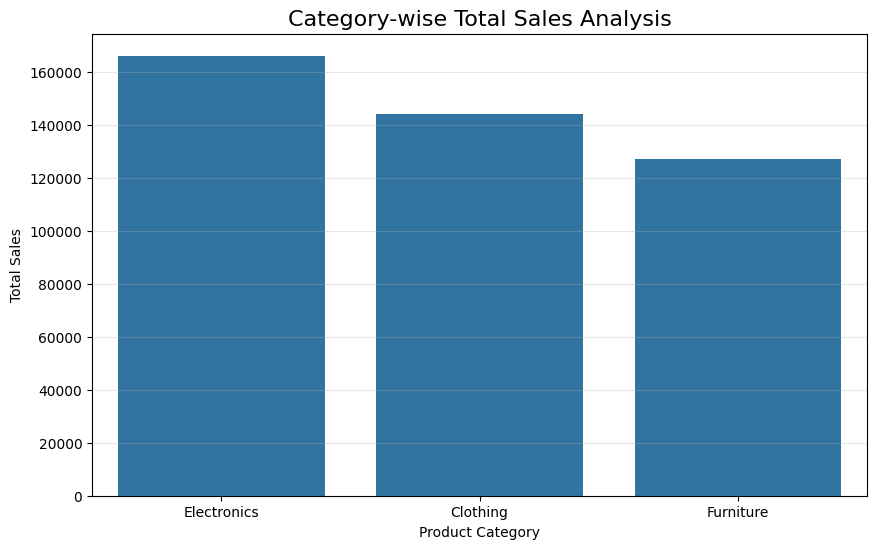

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title('Category-wise Total Sales Analysis',
          fontsize=16)

plt.xlabel('Product Category')

plt.ylabel('Total Sales')

plt.grid(axis='y', alpha=0.3)

plt.show()

In [ ]:
# Q3. Which category generates the highest and lowest average profit?

In [ ]:
# Average Profit Calculation :-

category_avg_profit = df.groupby('Category')['Profit'].mean().sort_values(ascending=False)

print(category_avg_profit)

Category
Furniture      43.111111
Electronics    42.733766
Clothing       14.041096
Name: Profit, dtype: float64


In [ ]:
# Highest aur Lowest Average Profit :-

print("Highest Average Profit:", category_avg_profit.idxmax())

print("Lowest Average Profit:", category_avg_profit.idxmin())

Highest Average Profit: Furniture
Lowest Average Profit: Clothing


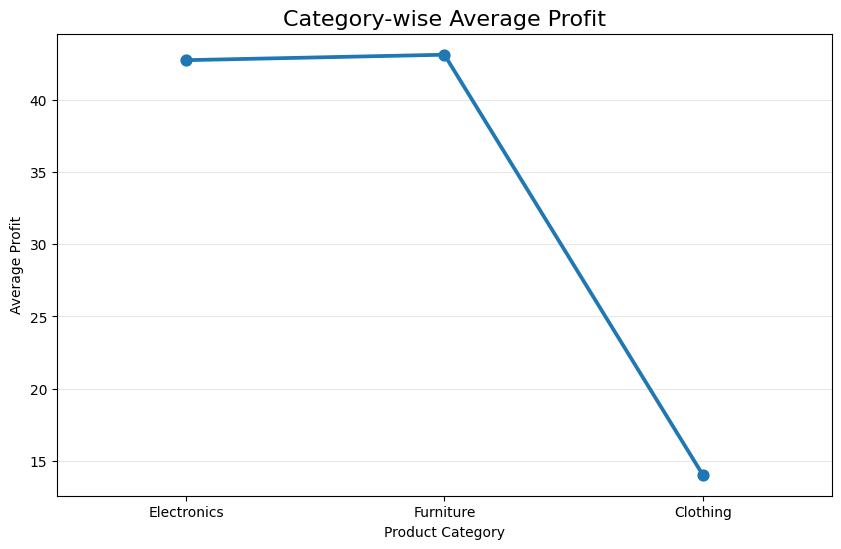

In [ ]:
# Visualization :-

plt.figure(figsize=(10, 6))

sns.pointplot(
    data=df,
    x='Category',
    y='Profit',
    estimator=np.mean,
    errorbar=None
)

plt.title('Category-wise Average Profit', fontsize=16)
plt.xlabel('Product Category')
plt.ylabel('Average Profit')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [ ]:
# Q4. Which category has the highest and lowest number of orders?

In [ ]:
# Category-wise Orders Count :-

category_orders = df.groupby('Category')['Order ID'].nunique().sort_values(ascending=False)

print(category_orders)

Category
Clothing       393
Electronics    204
Furniture      186
Name: Order ID, dtype: int64


In [ ]:
# Highest aur Lowest Orders :-

print("Highest Orders Category:", category_orders.idxmax())
print("Highest Number of Orders:", category_orders.max())

print("\nLowest Orders Category:", category_orders.idxmin())
print("Lowest Number of Orders:", category_orders.min())

Highest Orders Category: Clothing
Highest Number of Orders: 393

Lowest Orders Category: Furniture
Lowest Number of Orders: 186


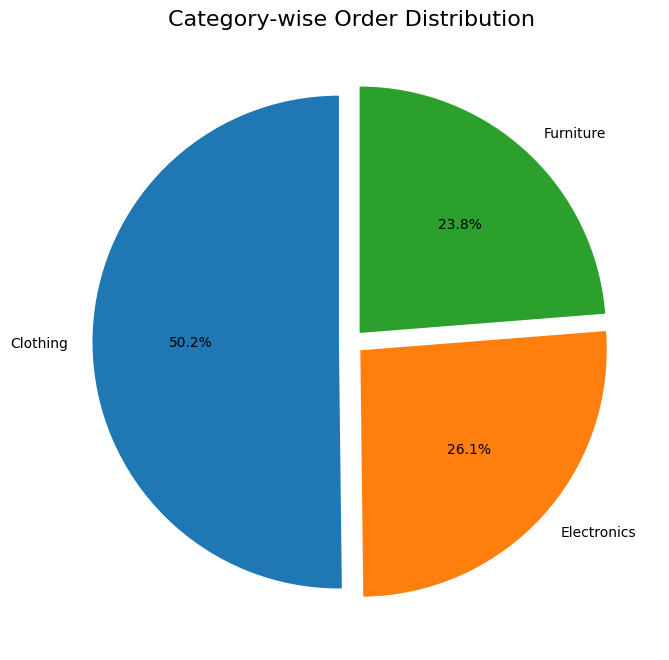

In [ ]:
# Visualization :-
plt.figure(figsize=(8, 8))

plt.pie(
    category_orders,
    labels=category_orders.index,
    autopct='%1.1f%%',
    startangle=90,
    explode=[0.05] * len(category_orders)
)

plt.title('Category-wise Order Distribution', fontsize=16)
plt.show()


In [ ]:
# Q5. Which sub-category generates the highest and lowest profit?

In [ ]:
# Sub-Category-wise Total Profit Calculation :-

subcategory_profit = df.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=False)

print(subcategory_profit)

Sub-Category
Printers            8606
Bookcases           6516
Saree               4057
Accessories         3353
Tables              3139
Trousers            2847
Stole               2431
Phones              1847
Hankerchief         1823
Chairs              1627
Shirt               1513
T-shirt             1500
Leggings            -130
Skirt               -315
Kurti               -401
Electronic Games    -644
Furnishings         -806
Name: Profit, dtype: int64


In [ ]:
# Highest aur Lowest Profit Find :-

print("Highest Profit Sub-Category:", subcategory_profit.idxmax())
print("Highest Total Profit:", subcategory_profit.max())

print("\nLowest Profit Sub-Category:", subcategory_profit.idxmin())
print("Lowest Total Profit:", subcategory_profit.min())

Highest Profit Sub-Category: Printers
Highest Total Profit: 8606

Lowest Profit Sub-Category: Furnishings
Lowest Total Profit: -806


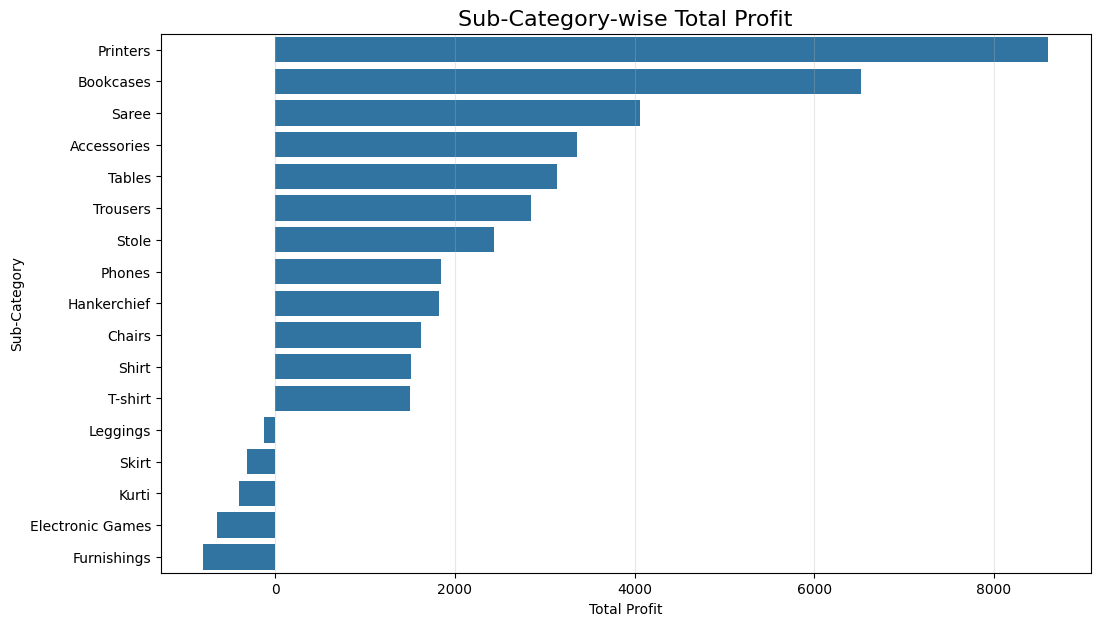

In [ ]:
# Visualization :-

plt.figure(figsize=(12, 7))

sns.barplot(
    x=subcategory_profit.values,
    y=subcategory_profit.index
)

plt.title('Sub-Category-wise Total Profit', fontsize=16)
plt.xlabel('Total Profit')
plt.ylabel('Sub-Category')
plt.grid(axis='x', alpha=0.3)

plt.show()

In [ ]:
# Q6. Which payment mode is most frequently used by customers?

In [ ]:
# Payment Mode Count :-

payment_count = df['PaymentMode'].value_counts()

print(payment_count)

PaymentMode
COD            684
UPI            331
Debit Card     202
Credit Card    163
EMI            120
Name: count, dtype: int64


In [ ]:
# Most aur Least Used Payment Mode :-

print("Most Used Payment Mode:", payment_count.idxmax())
print("Highest Number of Transactions:", payment_count.max())

print("\nLeast Used Payment Mode:", payment_count.idxmin())
print("Lowest Number of Transactions:", payment_count.min())

Most Used Payment Mode: COD
Highest Number of Transactions: 684

Least Used Payment Mode: EMI
Lowest Number of Transactions: 120


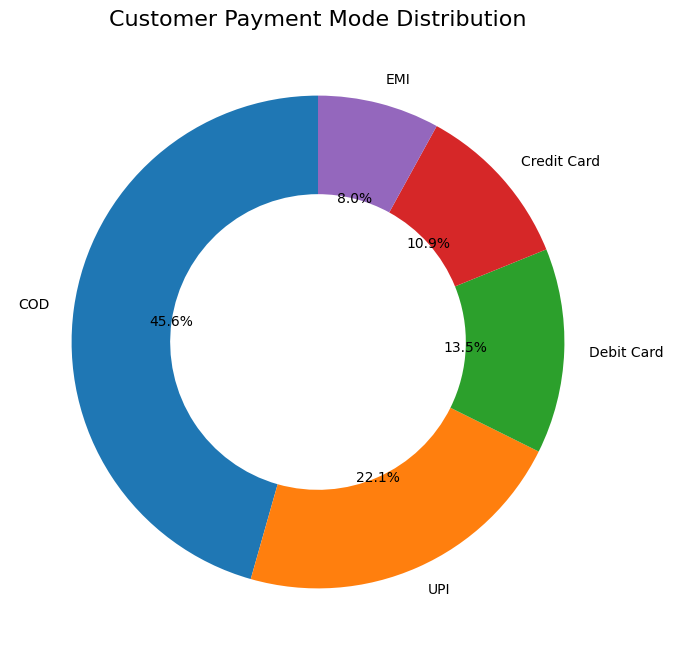

In [ ]:
# Visualization :-

plt.figure(figsize=(8, 8))

plt.pie(
    payment_count,
    labels=payment_count.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title('Customer Payment Mode Distribution', fontsize=16)

plt.show()

In [ ]:
# Q7. Which product categories generate profit and which categories generate losses?

In [ ]:
# Category-wise Total Profit Calculate :-

category_profit = df.groupby('Category')['Profit'].sum()

print(category_profit)

Category
Clothing       13325
Electronics    13162
Furniture      10476
Name: Profit, dtype: int64


In [ ]:
# Profit aur Loss Categories Identify :-

print("Profit Generating Categories:")
print(category_profit[category_profit > 0])

print("\nLoss Making Categories:")
print(category_profit[category_profit < 0])

Profit Generating Categories:
Category
Clothing       13325
Electronics    13162
Furniture      10476
Name: Profit, dtype: int64

Loss Making Categories:
Series([], Name: Profit, dtype: int64)


In [ ]:
# Highest aur Lowest Profit :-

print("Highest Profit Category:", category_profit.idxmax())
print("Highest Profit:", category_profit.max())

print("\nLowest Profit Category:", category_profit.idxmin())
print("Lowest Profit:", category_profit.min())

Highest Profit Category: Clothing
Highest Profit: 13325

Lowest Profit Category: Furniture
Lowest Profit: 10476


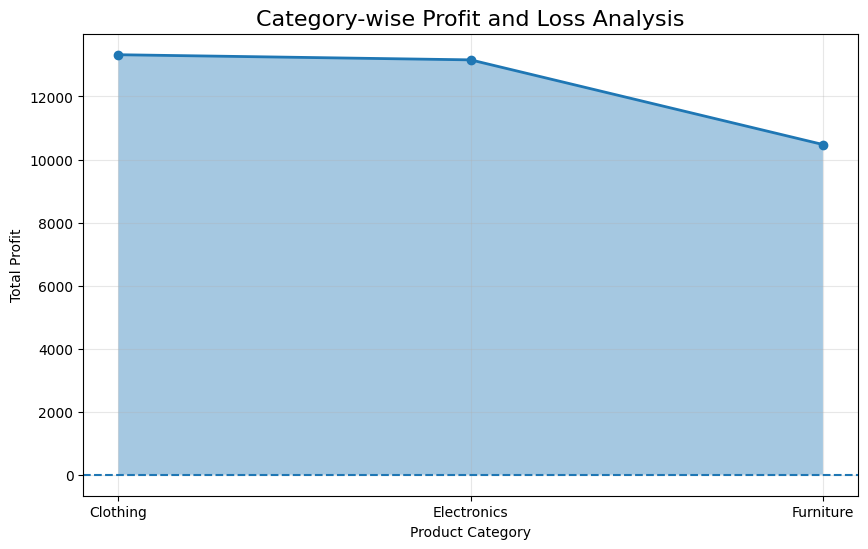

In [ ]:
# Visualization :-

plt.figure(figsize=(10, 6))

plt.fill_between(
    category_profit.index,
    category_profit.values,
    alpha=0.4
)

plt.plot(
    category_profit.index,
    category_profit.values,
    marker='o',
    linewidth=2
)

plt.axhline(y=0, linestyle='--')

plt.title('Category-wise Profit and Loss Analysis', fontsize=16)
plt.xlabel('Product Category')
plt.ylabel('Total Profit')
plt.grid(alpha=0.3)

plt.show()

# 📊 Sales Data Analysis (EDA)

## 📌 Project Overview

This project analyzes sales data to understand product performance, customer payment preferences, sales, and profit.

## 🎯 Objectives

* Analyze overall sales and profit.
* Find highest and lowest selling categories.
* Compare average profit by category.
* Analyze category-wise orders.
* Identify the most profitable sub-categories.
* Understand customer payment preferences.
* Identify profit and loss generating categories.

## 🛠️ Technologies Used

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Google Colab

## 📂 Dataset

The project uses `Sales_Data.xlsx` containing sales, product, order, payment, quantity, amount, and profit information.

## 📈 Visualizations

* Bar Chart
* Point Plot
* Pie Chart
* Donut Chart
* Area Chart

## 🔍 Key Analysis

The project explores sales performance, category-wise sales, average profit, order distribution, sub-category profit, payment modes, and profit/loss analysis.

## 📝 Conclusion

This project helps understand sales performance and identify profitable and loss-making product categories using data analysis and visualization.
